# Principles of AI: Search and Games

**DCS 404 · Data Science and Machine Learning**

---

Every other module in this course is about **learning from data**: fit a line, grow a tree, cluster some
points. This one isn't. Here we build programs that act intelligently with **no training data at all**. They
play Tic-Tac-Toe without ever losing, find the shortest way through a maze, and beat a random Connect Four
player every time. None of them learn anything. They **search**: they look at the possible futures and pick
the move that leads to the best one.

That's the first big lesson of this module, and of Chapter 1 of the course textbook: **machine learning is one
way to get artificial intelligence, not the only way.** Search, rules, and heuristics were the main way to
build AI for decades. They still run inside route planners, game engines, schedulers, and puzzle solvers
today, and they still sit next to learned models in systems like AlphaGo.

This notebook covers the Week 3 reading, *Artificial Intelligence and Machine Learning Fundamentals* (Nagy,
2018), **Chapter 1 — Principles of AI** and **Chapter 2 — AI with Search Techniques and Games**. Everything is
built from scratch in plain Python, so you can see exactly how each algorithm works.

## How to work through this

Run every code cell in order (`Shift + Enter`). Later sections reuse functions defined earlier: the
Tic-Tac-Toe board helpers from Section 5 are used again in Sections 6, 7, 9 and 10.

**Reading alongside the textbook.** Sections map to the book like this:

| This notebook | Textbook |
|---|---|
| 1–3. What AI is, agents, Python/NumPy | Chapter 1, pp. 1–15 |
| 4–5. BFS/DFS, the Tic-Tac-Toe state space | Chapter 1, pp. 16–27 (Exercises 2–3, Activity 1) |
| 6. Teaching the agent rules | Chapter 2, pp. 30–34 (Exercise 4, Activities 2–3) |
| 7. Heuristics | Chapter 2, pp. 35–42 (Exercise 5) |
| 8. Pathfinding with BFS and A* | Chapter 2, pp. 42–63 (Exercises 6–7) |
| 9–11. Minimax, alpha-beta, Negamax | Chapter 2, pp. 63–77 |
| 12. Connect Four | Chapter 2, Activity 4 |

The book's code has several bugs, some small and some that change the answer. This notebook fixes them as it
goes. Section 13 lists every correction in one place, so you can check what you read against what you run.

Nothing here needs a library beyond NumPy and Matplotlib. Every algorithm is written out by hand.

## Learning objectives

After completing this module you will be able to:

- Define AI and machine learning (Samuel's and Mitchell's definitions), and explain why **AI ⊃ ML**: why
  search-based agents count as AI with no learning at all.
- Describe an **intelligent agent** (sensors, actuators, goal) and write one as a function from percepts to
  actions.
- Model a problem as a **state space** (initial state, successor function, goal test) and explore it with
  **breadth-first** and **depth-first search**.
- Measure the **combinatorial explosion** of a game's state space, and use rules, symmetry and forced moves to
  shrink it.
- Explain what a **heuristic** is, and what makes one **admissible**.
- Implement **A\*** pathfinding, and explain why it finds the shortest path when greedy search doesn't.
- Implement **Minimax**, speed it up with **alpha-beta pruning**, and simplify it to **Negamax**, then build
  a Tic-Tac-Toe player that never loses.
- Write a depth-limited game AI with a heuristic evaluation for a game too large to search to the end
  (Connect Four).

## Setup

Run this once. It loads the libraries, sets the usual plotting style, and fixes a random seed so every
simulated game in this notebook comes out the same each time you run it.

In [1]:
import math
import heapq
import random
import time
from collections import deque, Counter
from itertools import permutations

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})
RANDOM_STATE = 0
rng = random.Random(RANDOM_STATE)

# Set to True to play against the AIs yourself (uses input(); leave False when running all cells)
INTERACTIVE = False
print("Ready.")

Ready.


---
## 1. What is AI, and how is it different from machine learning?

The textbook starts with three definitions worth knowing by heart:

> **Artificial Intelligence** is a science that's used to construct intelligence using hardware and software
> solutions.

> **Machine learning** is a field of study concerned with giving computers the ability to learn without being
> explicitly programmed. *(Arthur Samuel, 1959)*

> A computer program is said to **learn** from experience $E$ with respect to a task $T$ and a performance
> measure $P$, if its performance on $T$, as measured by $P$, improves with experience $E$.
> *(Tom Mitchell, 1997)*

Mitchell's definition is the useful one, because you can check it. Spam filtering: $T$ = label emails,
$P$ = accuracy, $E$ = a pile of emails humans have already labelled. Every model in the later modules of this
course fits that pattern.

Now the key point. **You can build AI without machine learning.** If you hard-code rules, or search through
possible futures, your program can act intelligently with no experience $E$ at all. All of this module works
that way:

| Approach | Where the "intelligence" comes from | Example in this course |
|---|---|---|
| **Rules** | A human writes them down | Section 6: "if you can win, win; if they can win, block" |
| **Search** | Looking ahead at possible futures | Sections 8–12: A*, Minimax |
| **Machine learning** | Patterns found in data | Regression, Decision Trees, K-Means, Neural Networks |

### Why it takes many disciplines

A self-driving car has to *sense* other cars (computer vision), *predict* where they'll go (statistics),
*plan* a route (graph theory and search), and *move* the wheels (control theory and robotics). The book lists
the disciplines AI borrows from: robotics, algorithm theory, statistics, psychology, software engineering,
mathematics, control theory, information theory, graph theory, physics, and computer graphics.

### Fields of AI, by the human ability they copy

| Human ability | AI field | Everyday example |
|---|---|---|
| Listening and speaking | Speech recognition and synthesis | Voice assistants, live translation |
| Understanding language | Natural Language Processing (NLP) | Chatbots, search engines |
| Remembering things | Knowledge bases and ontologies | Google's Knowledge Graph |
| Thinking | Expert systems, neural networks | Medical diagnosis support |
| Seeing | Computer vision | Face unlock, medical imaging |
| Moving | Robotics and control theory | Warehouse robots, drones |

### The Turing test

Alan Turing proposed testing intelligence by conversation. A judge chats by text with a human and a machine.
If the judge can't reliably tell which is which, the machine passes. The textbook (2018) predicted this
wouldn't happen until "the late 2020s". **That prediction has aged fast.** In a 2025 study (Jones & Bergen),
judges picked GPT-4.5 as the human 73% of the time when it was prompted to adopt a persona. Large language
models have changed this part of the field more than any other since the book was written. The *Total*
Turing test, which adds vision and physical movement, is still far off.

### Two kinds of reasoning, two kinds of learning

- **Classification** works out what category something belongs to ("Jane is female and a parent, so Jane is
  a mother"). **Prediction** estimates something from patterns ("someone who buys organic milk is more likely
  to buy organic yoghurt").
- **Supervised learning** learns from labelled examples (Regression, Logistic Regression, Decision Trees,
  KNN). **Unsupervised learning** finds structure without labels (K-Means). Both get full modules later in
  the course.

---
## 2. Intelligent agents

The central object in AI (and in this module) is the **agent**. The textbook defines an intelligent agent as
something that:

- is **autonomous**,
- **observes** its surroundings through **sensors**,
- **acts** on its environment through **actuators**, and
- directs its activity toward a **goal**.

Put simply: **an agent is a function from what it perceives to what it does.** Let's write one. Here is the
classic *vacuum world*: two rooms, `A` and `B`, each either clean or dirty. The vacuum's sensors tell it which
room it's in and whether that room is dirty. Its actuators can `Suck`, or move `Left` / `Right`.

In [2]:
def reflex_vacuum_agent(percept):
    '''A simple reflex agent: the action depends only on the current percept.'''
    location, is_dirty = percept
    if is_dirty:
        return "Suck"
    return "Right" if location == "A" else "Left"

def run_vacuum_world(agent, dirt, location="A", steps=6):
    dirt = dict(dirt)                                   # don't mutate the caller's dict
    score = 0
    for t in range(steps):
        percept = (location, dirt[location])            # sensors
        action = agent(percept)                         # the agent decides
        if action == "Suck" and dirt[location]:         # actuators change the world
            dirt[location] = False
            score += 10                                 # reward for cleaning
        elif action in ("Left", "Right"):
            location = "A" if action == "Left" else "B"
            score -= 1                                  # small cost for moving
        print(f"t={t}  percept={percept!s:<14} action={action:<6} world={dirt}")
    print(f"Performance score: {score}")

run_vacuum_world(reflex_vacuum_agent, dirt={"A": True, "B": True})

t=0  percept=('A', True)    action=Suck   world={'A': False, 'B': True}
t=1  percept=('A', False)   action=Right  world={'A': False, 'B': True}
t=2  percept=('B', True)    action=Suck   world={'A': False, 'B': False}
t=3  percept=('B', False)   action=Left   world={'A': False, 'B': False}
t=4  percept=('A', False)   action=Right  world={'A': False, 'B': False}
t=5  percept=('B', False)   action=Left   world={'A': False, 'B': False}
Performance score: 16


Both rooms are clean after three steps, and the agent never "learned" anything. Its designer wrote the rules
in advance. Two ideas from this toy come back in every later section:

1. **Performance measure.** We judged the agent by a score (+10 per clean, −1 per move). The textbook calls
   this the "carrot and stick": good actions are rewarded and bad ones punished. A game AI's goal is the same
   in principle: get the highest score, where winning is the top score.
2. **The agent wastes moves.** After both rooms are clean it keeps going back and forth (`Left`, `Right`, …),
   because a *reflex* agent can't think ahead. Agents that **look ahead** at the consequences of their actions
   are what the rest of this module builds.

---
## 3. Python and NumPy warm-up (textbook Exercise 1)

The book uses Python because it is readable, quick to write, and has the best set of AI/ML libraries: NumPy,
SciPy, pandas, scikit-learn, NLTK, TensorFlow, PyTorch. You met NumPy on DataCamp in Week 2. Here is the
book's Exercise 1, *updated*: the book uses `np.mat`, which **was removed in NumPy 2.0**. Use a normal
`np.array` and the `@` operator for matrix multiplication.

In [3]:
A = np.array([[1, 2, 3],
              [4, 5, 6],
              [7, 8, 9]])

print("A @ A  (matrix product, i.e. the 'square' of A):")
print(A @ A)
print("\nA * A  (element-wise -- NOT the matrix product, a classic mistake):")
print(A * A)
print("\nTranspose A.T:")
print(A.T)
print(f"\nnp.linalg.det(A) = {np.linalg.det(A)!r}")
print(f"Exact determinant by hand: {1*5*9 + 2*6*7 + 3*4*8 - 1*6*8 - 2*4*9 - 3*5*7}")

A @ A  (matrix product, i.e. the 'square' of A):
[[ 30  36  42]
 [ 66  81  96]
 [102 126 150]]

A * A  (element-wise -- NOT the matrix product, a classic mistake):
[[ 1  4  9]
 [16 25 36]
 [49 64 81]]

Transpose A.T:
[[1 4 7]
 [2 5 8]
 [3 6 9]]

np.linalg.det(A) = np.float64(-9.51619735392994e-16)
Exact determinant by hand: 0


Two lessons:

- `@` is matrix multiplication. `*` multiplies cell by cell. The top-left cell of `A @ A` is
  $1\cdot1 + 2\cdot4 + 3\cdot7 = 30$: row 1 of $A$ dotted with column 1 of $A$.
- The determinant is exactly **0** (row 3 − row 2 = row 2 − row 1, so the rows are linearly dependent). NumPy
  returns a tiny non-zero number instead. That's **floating-point rounding**, not a bug. Never test float
  results with `==`; use `np.isclose`.

In [4]:
print(np.linalg.det(A) == 0)          # False -- rounding error
print(np.isclose(np.linalg.det(A), 0))  # True  -- the right way to compare floats

False
True


---
## 4. Problems as search: breadth-first and depth-first search

To make an agent look ahead, we describe the problem as a **state space**:

- an **initial state**, where we start;
- a **successor function** `succ(state)`, the states reachable in one action;
- a **goal test**, which says whether we're done.

Starting at the initial state and applying `succ` over and over builds a **search tree**. The root is the
start, each edge is an action, and leaves are states with no successors. **Search algorithms differ only in
the order they visit the tree.**

The book's toy problem: start at `1`. Each step adds **1 or 2**. Stop at **5**.

In [5]:
def succ(node):
    value, depth = node
    if value == 5:
        return []                                   # goal: a leaf
    if value == 4:
        return [(5, depth + 1)]                     # can't jump past 5
    return [(value + 1, depth + 1), (value + 2, depth + 1)]

root = (1, 1)   # (value, depth)

def bfs_tree(root):
    to_visit = deque([root])          # a QUEUE: first in, first out
    visited = []
    while to_visit:
        node = to_visit.popleft()
        visited.append(node)
        to_visit.extend(succ(node))
    return visited

def dfs_tree(root):
    to_visit = [root]                 # a STACK: last in, first out
    visited = []
    while to_visit:
        node = to_visit.pop()
        visited.append(node)
        to_visit.extend(succ(node))
    return visited

bfs_order, dfs_order = bfs_tree(root), dfs_tree(root)
print("BFS visits (value, depth):", bfs_order)
print("DFS visits (value, depth):", dfs_order)

BFS visits (value, depth): [(1, 1), (2, 2), (3, 2), (3, 3), (4, 3), (4, 3), (5, 3), (4, 4), (5, 4), (5, 4), (5, 4), (5, 5)]
DFS visits (value, depth): [(1, 1), (3, 2), (5, 3), (4, 3), (5, 4), (2, 2), (4, 3), (5, 4), (3, 3), (5, 4), (4, 4), (5, 5)]


The **only** difference between the two functions is `popleft()` (queue) versus `pop()` (stack). It's easier
to see on the tree itself. The number in each node's corner is the order it was visited:

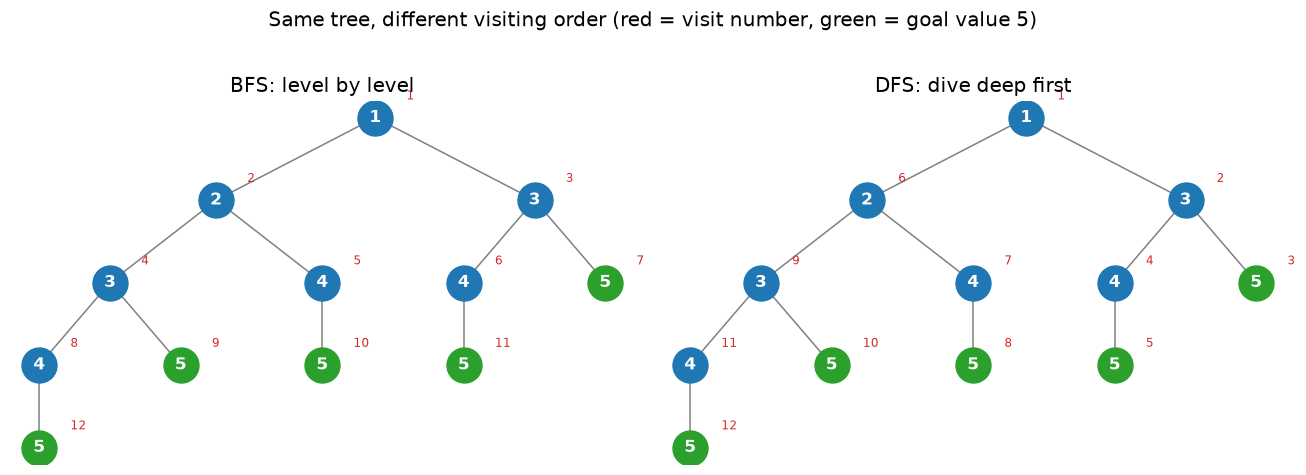

In [6]:
def build_tree(node, path=()):
    '''Return a nested dict {'node': (value, depth), 'id': path, 'children': [...]}.'''
    return {"node": node, "id": path,
            "children": [build_tree(c, path + (i,)) for i, c in enumerate(succ(node))]}

def layout(tree, x=0.0, positions=None):
    '''Assign x positions so leaves are evenly spaced; returns (positions, next_free_x).'''
    positions = {} if positions is None else positions
    if not tree["children"]:
        positions[tree["id"]] = (x, -tree["node"][1]); return positions, x + 1
    xs = []
    for ch in tree["children"]:
        positions, x = layout(ch, x, positions); xs.append(positions[ch["id"]][0])
    positions[tree["id"]] = (sum(xs) / len(xs), -tree["node"][1])
    return positions, x

def visit_rank(tree, order_fn):
    '''Map each tree-node id to its visit number under BFS/DFS (same traversal, on ids).'''
    ranks, frontier = {}, deque([tree]) if order_fn == "bfs" else [tree]
    while frontier:
        t = frontier.popleft() if order_fn == "bfs" else frontier.pop()
        ranks[t["id"]] = len(ranks) + 1
        frontier.extend(t["children"])
    return ranks

def draw_tree(tree, ranks, ax, title):
    pos, _ = layout(tree)
    def edges(t):
        for ch in t["children"]:
            (x0, y0), (x1, y1) = pos[t["id"]], pos[ch["id"]]
            ax.plot([x0, x1], [y0, y1], color="grey", lw=1, zorder=1); edges(ch)
    edges(tree)
    def nodes(t):
        x, y = pos[t["id"]]; v = t["node"][0]
        ax.scatter(x, y, s=520, color="tab:green" if v == 5 else "tab:blue", zorder=2)
        ax.text(x, y, str(v), ha="center", va="center", color="white", fontweight="bold", zorder=3)
        ax.text(x + 0.22, y + 0.22, str(ranks[t["id"]]), fontsize=8, color="tab:red", zorder=3)
        for ch in t["children"]: nodes(ch)
    nodes(tree)
    ax.set_title(title); ax.axis("off")

tree = build_tree(root)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
draw_tree(tree, visit_rank(tree, "bfs"), axes[0], "BFS: level by level")
draw_tree(tree, visit_rank(tree, "dfs"), axes[1], "DFS: dive deep first")
plt.suptitle("Same tree, different visiting order (red = visit number, green = goal value 5)", y=1.02)
plt.tight_layout(); plt.show()

- **BFS** visits level by level, so the **first goal it reaches is the shallowest one**. Here that's 5 at
  depth 3 (`1 → 3 → 5`). For problems where every step costs the same, BFS finds a shortest path.
- **DFS** dives straight down one branch first. It uses little memory but doesn't guarantee the shortest
  path. In a huge tree like chess it can get lost down one very deep branch.

**Trees vs graphs.** If two different paths can reach the *same* state (and in Tic-Tac-Toe they can), you
should keep a **visited set** and skip states you've already seen. Otherwise you do the same work again and
again. Section 8 shows exactly how much that costs.

---
## 5. The state space of Tic-Tac-Toe

Two players take turns on a 3×3 board. `X` moves first. Three in a row, column, or diagonal wins. Like the
book, we store the board as a **9-character string**, cells indexed like this:

```
 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8
```

Our AI plays `X` and moves first. The opponent plays `O`.

In [7]:
EMPTY, AI, OPP = ".", "X", "O"
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8),      # rows
         (0, 3, 6), (1, 4, 7), (2, 5, 8),      # columns
         (0, 4, 8), (2, 4, 6)]                 # diagonals

def other(sign):
    return OPP if sign == AI else AI

def winner(board):
    '''Return 'X' or 'O' if someone has three in a line, else EMPTY.'''
    for i, j, k in LINES:
        if board[i] == board[j] == board[k] != EMPTY:
            return board[i]
    return EMPTY

def is_over(board):
    return winner(board) != EMPTY or EMPTY not in board

def all_moves(board, sign):
    '''The successor function: every board reachable by `sign` placing one mark.'''
    return [board[:i] + sign + board[i + 1:] for i, c in enumerate(board) if c == EMPTY]

def print_board(board):
    for r in range(3):
        print(" " + " | ".join(board[3 * r:3 * r + 3]))
    print()

def draw_board(board, ax, title="", values=None):
    '''Draw a board; optional `values` (len 9) are printed small in empty cells (used for heuristics).'''
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect("equal"); ax.axis("off")
    for k in (1, 2):
        ax.plot([k, k], [0, 3], color="black", lw=2); ax.plot([0, 3], [k, k], color="black", lw=2)
    for i, c in enumerate(board):
        x, y = i % 3 + 0.5, 2.5 - i // 3
        if c != EMPTY:
            ax.text(x, y, c, ha="center", va="center", fontsize=28, fontweight="bold",
                    color="tab:blue" if c == AI else "tab:red")
        elif values is not None:
            ax.text(x, y, str(values[i]), ha="center", va="center", fontsize=13, color="tab:green")
        else:
            ax.text(x + 0.33, y - 0.33, str(i), fontsize=8, color="lightgrey")
    ax.set_title(title, fontsize=11)

example = "X...O...X"        # the book's example: X at 0, O at 4, X at 8
print_board(example)
print("winner:", repr(winner(example)), "| game over:", is_over(example))
print("O's possible next boards:", all_moves(example, OPP))

 X | . | .
 . | O | .
 . | . | X

winner: '.' | game over: False
O's possible next boards: ['XO..O...X', 'X.O.O...X', 'X..OO...X', 'X...OO..X', 'X...O.O.X', 'X...O..OX']


### How big is the game? (textbook Exercise 2)

A rough upper bound: the first player has 9 choices, the second 8, then 7, … so at most
$9! = 362{,}880$ move sequences. Many games end early with a win, so the true number is smaller. We don't
have to estimate it, though. A short recursive search can **count every possible game exactly**:

In [8]:
def count_games(board=EMPTY * 9, turn=AI):
    '''Exhaustively play out every legal game; return a Counter of outcomes.'''
    w = winner(board)
    if w != EMPTY:
        return Counter({w: 1})
    if EMPTY not in board:
        return Counter({"draw": 1})
    total = Counter()
    for nxt in all_moves(board, turn):
        total += count_games(nxt, other(turn))
    return total

t0 = time.time()
outcomes = count_games()
print(f"9! upper bound:       {math.factorial(9):,}")
print(f"Actual distinct games: {sum(outcomes.values()):,}   ({time.time() - t0:.1f}s)")
print(f"  X (first player) wins: {outcomes['X']:,}")
print(f"  O (second player) wins: {outcomes['O']:,}")
print(f"  draws:                  {outcomes['draw']:,}")

9! upper bound:       362,880
Actual distinct games: 255,168   (0.6s)
  X (first player) wins: 131,184
  O (second player) wins: 77,904
  draws:                  46,080


That's **255,168** possible games for a game children solve at the kitchen table. Our numbers match the
research figures the book quotes (131,184 / 77,904 / 46,080). Here is how fast the tree grows, move by move:

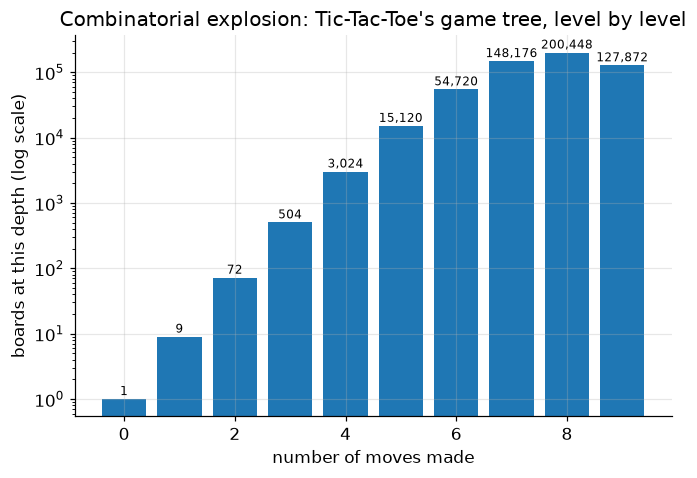

In [9]:
def states_per_depth():
    level, sizes = [EMPTY * 9], [1]
    for step in range(9):
        sign = AI if step % 2 == 0 else OPP
        level = [n for b in level for n in all_moves(b, sign)]
        sizes.append(len(level))
        level = [b for b in level if winner(b) == EMPTY]   # finished games stop growing
    return sizes

sizes = states_per_depth()
plt.bar(range(10), sizes, color="tab:blue")
plt.yscale("log")
for d, s in enumerate(sizes):
    plt.text(d, s * 1.15, f"{s:,}", ha="center", fontsize=8)
plt.xlabel("number of moves made"); plt.ylabel("boards at this depth (log scale)")
plt.title("Combinatorial explosion: Tic-Tac-Toe's game tree, level by level")
plt.show()

Note the **log scale**: each bar is roughly 5–8× the one before it, until wins start ending games. Chess
starts with 20 legal moves instead of 9, and games last about 40 moves per side, not 4–5. No computer can list
every chess game. **This explosion is why the rest of the module exists.** Every technique that follows is a
way to avoid looking at most of this tree.

> **⚠️ Textbook check: why the book says 266,073.** The book's Activity 1 reports 266,073 games, which is
> *more* than the true 255,168. That's impossible, and its own note quotes the correct figure. The cause is
> its `filter_wins` function, which calls `list.remove()` **while looping over the same list**. Removing an
> item shifts the rest of the list left, so the loop skips whatever comes next. If that next board was also
> a finished game, it never gets filtered out, and its "children" get counted too. A three-line demo:

In [10]:
numbers = [1, 2, 2, 3]
for n in numbers:
    if n == 2:
        numbers.remove(n)      # mutating the list we're iterating over...
print(numbers)                 # ...leaves a 2 behind: the second 2 was skipped

numbers = [1, 2, 2, 3]
numbers = [n for n in numbers if n != 2]   # the safe way: build a new list
print(numbers)

[1, 2, 3]
[1, 3]


### A random player (textbook Exercise 3)

The simplest possible agent picks any empty cell at random. Below, two random players face each other 10,000
times. The book's version asks for the human's move with `input()`. To play yourself, set `INTERACTIVE = True`
in Setup and run the `play_vs` cell at the end of Section 9.

In [11]:
def random_policy(board, sign):
    return rng.choice(all_moves(board, sign))

def play_game(policy_x, policy_o, start=EMPTY * 9):
    '''Play one game; return the final board.'''
    board, turn = start, AI
    while not is_over(board):
        board = (policy_x if turn == AI else policy_o)(board, turn)
        turn = other(turn)
    return board

def tournament(policy_x, policy_o, n=1000):
    results = Counter()
    for _ in range(n):
        w = winner(play_game(policy_x, policy_o))
        results["X wins" if w == AI else "O wins" if w == OPP else "draw"] += 1
    return {k: results[k] for k in ("X wins", "O wins", "draw")}

rand_vs_rand = tournament(random_policy, random_policy, n=10_000)
print("random X vs random O, 10,000 games:", rand_vs_rand)

random X vs random O, 10,000 games: {'X wins': 5857, 'O wins': 2841, 'draw': 1302}


Even with no strategy at all, **moving first is a big advantage**: X wins far more often than O. But the
random X still loses a lot of games, games where any child could have spotted the win or the block. Let's fix
that.

---
## 6. Teaching the agent with rules (textbook Exercise 4, Activities 2–3)

We'll improve the X player in three steps, adding one rule at a time. After each step we check it in two
ways:

1. **Exhaustive check.** Play X's policy against **every possible** O reply, and count every possible game.
   This is a *guarantee*: if no game in this count is a loss, X can never lose.
2. **Tournament.** Play 1,000 games against a random O, the kind of opponent you'd actually meet.

The rules come straight from how people play:

| Policy | Rule added |
|---|---|
| `random` | Pick any empty cell |
| `win` | **If you can win right now, do it** (Exercise 4) |
| `win+block` | …and otherwise **never leave the opponent a winning move** (Activity 2) |
| `fixed opening` | …and **hard-code the first two moves**: take a corner, then the opposite corner, or the centre if that corner is taken (Activity 3) |

In [12]:
def opponent_can_win(board, opp_sign):
    return any(winner(b) == opp_sign for b in all_moves(board, opp_sign))

# Each "rule" function returns the LIST of moves the policy is willing to make (exhaustive check uses all
# of them; the tournament picks one at random).
def moves_random(board, sign):
    return all_moves(board, sign)

def moves_win(board, sign):
    options = all_moves(board, sign)
    winning = [b for b in options if winner(b) == sign]
    return winning[:1] or options

def moves_win_block(board, sign):
    winning = moves_win(board, sign)
    if winner(winning[0]) == sign:
        return winning
    safe = [b for b in winning if not opponent_can_win(b, other(sign))]
    return safe or winning                      # if nothing is safe, we've lost anyway

def moves_fixed_opening(board, sign):
    empties = board.count(EMPTY)
    if empties == 9:                            # move 1: top-left corner
        return [sign + EMPTY * 8]
    if empties == 7:                            # move 2: opposite corner, else centre
        return [board[:8] + sign] if board[8] == EMPTY else [board[:4] + sign + board[5:]]
    return moves_win_block(board, sign)

POLICIES = {"random": moves_random, "win": moves_win,
            "win+block": moves_win_block, "fixed opening": moves_fixed_opening}

def exhaustive(x_moves):
    '''Count every game when X follows `x_moves` and O may play ANY legal move.'''
    def go(board, turn):
        w = winner(board)
        if w != EMPTY: return Counter({w: 1})
        if EMPTY not in board: return Counter({"draw": 1})
        nxt = x_moves(board, AI) if turn == AI else all_moves(board, OPP)
        return sum((go(b, other(turn)) for b in nxt), Counter())
    return go(EMPTY * 9, AI)

rows = []
for name, mv in POLICIES.items():
    ex = exhaustive(mv)
    policy = lambda b, s, mv=mv: rng.choice(mv(b, s))
    tour = tournament(policy, random_policy, n=1000)
    rows.append((name, sum(ex.values()), ex["X"], ex["O"], ex["draw"], tour))
    print(f"{name:14s} | games to consider: {sum(ex.values()):>7,} | X wins {ex['X']:>7,} "
          f"| X LOSES {ex['O']:>6,} | draws {ex['draw']:>6,} || vs random O: {tour}")

random         | games to consider: 255,168 | X wins 131,184 | X LOSES 77,904 | draws 46,080 || vs random O: {'X wins': 608, 'O wins': 280, 'draw': 112}


win            | games to consider:  91,360 | X wins  40,352 | X LOSES 27,008 | draws 24,000 || vs random O: {'X wins': 830, 'O wins': 105, 'draw': 65}


win+block      | games to consider:  45,824 | X wins  25,344 | X LOSES  3,776 | draws 16,704 || vs random O: {'X wins': 893, 'O wins': 18, 'draw': 89}
fixed opening  | games to consider:     188 | X wins     140 | X LOSES      0 | draws     48 || vs random O: {'X wins': 961, 'O wins': 0, 'draw': 39}


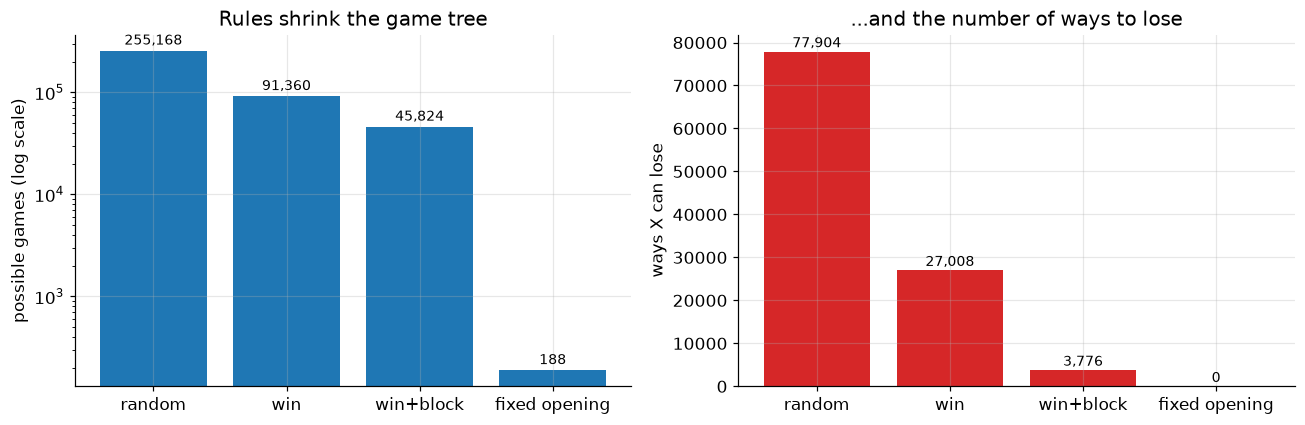

In [13]:
names = [r[0] for r in rows]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(names, [r[1] for r in rows], color="tab:blue")
axes[0].set_yscale("log"); axes[0].set_ylabel("possible games (log scale)")
axes[0].set_title("Rules shrink the game tree")
for i, r in enumerate(rows):
    axes[0].text(i, r[1] * 1.15, f"{r[1]:,}", ha="center", fontsize=9)
axes[1].bar(names, [r[3] for r in rows], color="tab:red")
axes[1].set_ylabel("ways X can lose")
axes[1].set_title("...and the number of ways to lose")
for i, r in enumerate(rows):
    axes[1].text(i, r[3] + 1000, f"{r[3]:,}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

Read the table from top to bottom:

- **`win`**: one rule cuts the tree from 255,168 games to about a third of that, and wins against a random
  opponent go up sharply.
- **`win+block`**: losses drop sharply, but X **can still lose**. The exhaustive count shows exactly how many
  losing lines are left. The cause is **forks**: O makes two threats at once, and blocking one leaves the
  other open.
- **`fixed opening`**: two hard-coded moves cut the whole tree to **188 games**, and **none of them are X
  losses**. Because the count covers every possible O reply, this isn't luck. It's a proof that this agent
  can't lose.

> **Textbook check.** The book's counts for these activities (91,344, then 42,048, then 188) don't match ours
> exactly. They were produced by the same buggy `filter_wins` from Section 5. The conclusions still hold:
> each rule shrinks the tree, `win+block` can still lose, and the fixed opening can't.

The book sums up the tricks we used to shrink the state space. Each one comes back later in this module:

1. **Empirical simplification**: hard-code moves you know are good (the corner opening).
2. **Symmetry**: the four corners are equivalent, because rotating the board turns one into another.
3. **Merging permutations**: moves A, X, B and B, X, A reach the *same* board, so explore it once.
4. **Forced moves for us**: if we can complete a line, or must block one, there's only one move to consider.
5. **Forced moves for the opponent**: assume they'll make the obvious winning or blocking move.
6. **Random move**: a last resort when we can't search.

Hand-written rules worked here, but someone had to *find* them. That was easy for Tic-Tac-Toe and is hopeless
for chess. The next step is to let the program **score** positions and **search** for good moves itself.

---
## 7. Heuristics: educated guesses that guide search

BFS and DFS are **uninformed** searches. They treat every branch the same and know nothing about the problem.
An **informed** search uses a **heuristic**, a function that makes an *educated guess* about how good a state
or move is. The book lists three kinds of guess:

- how useful a **move** is,
- how good a **game state** is for a player,
- how far a state is from the **goal** (for pathfinding).

The book uses **utility** and **cost** as opposites: maximising utility is the same as minimising cost.

### Heuristic 1 — evaluate only finished games

$+1$ if the AI has won, $-1$ if it has lost, $0$ otherwise. It's always correct, but **almost always zero**:
nobody can win in fewer than 5 moves, so it tells an opening player nothing. A heuristic is only useful if it
can tell *non-final* positions apart.

### Heuristic 2 — score every empty cell (textbook Exercise 5)

Look at all 8 lines. For each line, add points to its empty cells:

| Pattern in a line | Points to each empty cell in it | Meaning |
|---|---|---|
| two X + one empty | **+1000** | win now |
| two O + one empty | **+100** | must block |
| one X + two empty | **+10** | build a threat |
| three empty | **+1** | keep options open |

Why powers of ten? A cell sits on at most 4 lines, so lower-tier points can never add up to beat one
higher-tier rule ($4 \times 10 < 100$). Winning always beats blocking, and blocking always beats building.

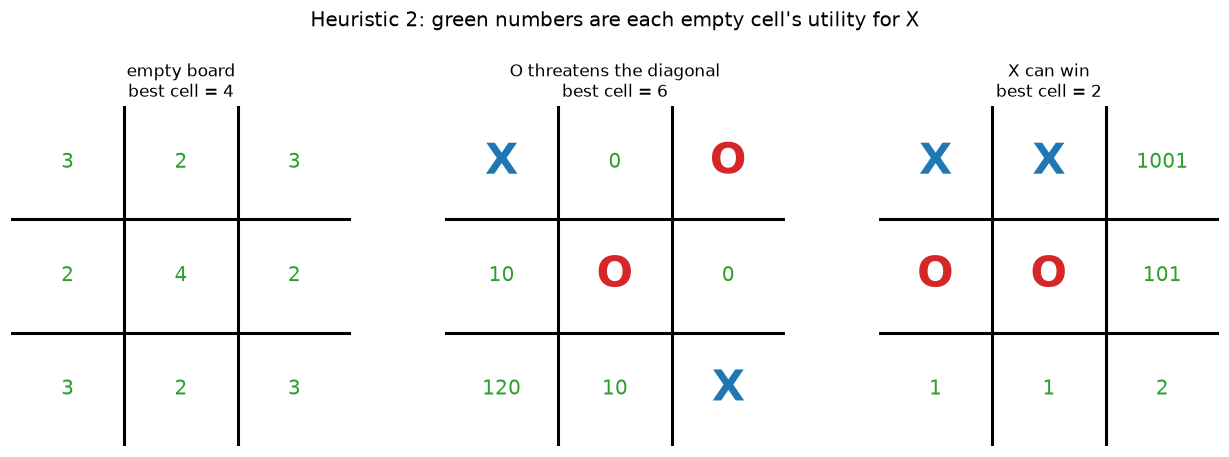

In [14]:
def utility_matrix(board, me=AI):
    opp = other(me)
    util = [0 if c == EMPTY else -1 for c in board]       # occupied cells: never choose
    for line in LINES:
        cells = [board[i] for i in line]
        empties = cells.count(EMPTY)
        if empties == 1 and cells.count(me) == 2:     pts = 1000
        elif empties == 1 and cells.count(opp) == 2:  pts = 100
        elif empties == 2 and cells.count(me) == 1:   pts = 10
        elif empties == 3:                             pts = 1
        else:                                          continue
        for i in line:
            if util[i] >= 0:
                util[i] += pts
    return util

boards = {"empty board": EMPTY * 9,
          "O threatens the diagonal": "X.O.O...X",
          "X can win": "XX.OO...."}
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, b) in zip(axes, boards.items()):
    u = utility_matrix(b)
    draw_board(b, ax, f"{title}\nbest cell = {int(np.argmax(u))}", values=[v if v >= 0 else "" for v in u])
plt.suptitle("Heuristic 2: green numbers are each empty cell's utility for X", y=1.03)
plt.tight_layout(); plt.show()

- **Empty board**: the centre scores highest (4: it's on 4 lines), then corners (3), then edges (2). The
  heuristic finds "take the centre" without anyone telling it.
- **O threatens the diagonal**: the blocking cell gets +100 and wins clearly.
- **X can win**: the winning cell gets +1000. Blocking O's row is worth only 100, so the heuristic correctly
  prefers to win.

Now let's make it a player: always choose a cell with the highest utility. We run the same exhaustive check
as Section 6 twice, once with the heuristic playing **X** (moving first) and once playing **O** (moving
second), each time against an opponent that may try *every* possible move.

In [15]:
def moves_heuristic(board, sign):
    util = utility_matrix(board, me=sign)
    best = max(util)
    return [board[:i] + sign + board[i + 1:] for i, u in enumerate(util) if u == best]

def exhaustive_for(sign_with_policy, policy_moves):
    '''Every game where `sign_with_policy` follows policy_moves and the other side tries everything.'''
    def go(board, turn):
        w = winner(board)
        if w != EMPTY: return Counter({w: 1})
        if EMPTY not in board: return Counter({"draw": 1})
        nxt = policy_moves(board, turn) if turn == sign_with_policy else all_moves(board, turn)
        return sum((go(b, other(turn)) for b in nxt), Counter())
    return go(EMPTY * 9, AI)

for sign in (AI, OPP):
    ex = exhaustive_for(sign, moves_heuristic)
    print(f"heuristic plays {sign} | games to consider: {sum(ex.values()):>5,} | heuristic wins "
          f"{ex[sign]:>5,} | heuristic LOSES {ex[other(sign)]:>4,} | draws {ex['draw']:>4,}")

heuristic plays X | games to consider:   248 | heuristic wins   224 | heuristic LOSES    0 | draws   24
heuristic plays O | games to consider: 1,992 | heuristic wins 1,552 | heuristic LOSES  120 | draws  320


Two very different results:

- **Moving first, the heuristic never loses.** It picks up "take the centre", "block", and "win when you
  can" from its scores, with no hard-coded opening. (The book reports 12 losses here. That number comes from
  the same counting bug as Section 5.)
- **Moving second, it can lose**, in 120 different ways. Here is one of those games:

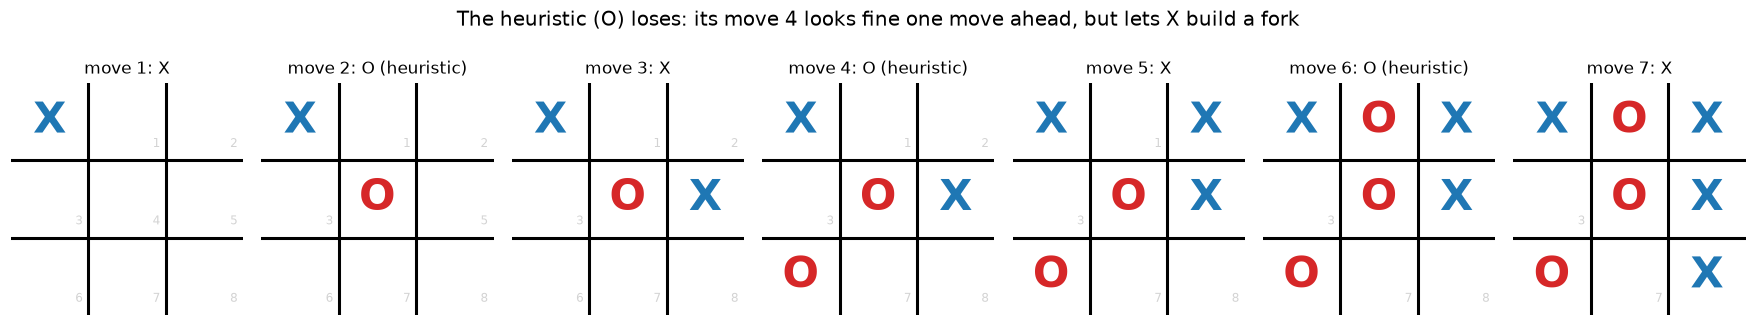

In [16]:
def find_loss(policy_sign, policy_moves, board=EMPTY * 9, turn=AI, line=()):
    '''Depth-first search for one game the policy loses; returns the list of boards.'''
    w = winner(board)
    if w == other(policy_sign): return list(line)
    if w != EMPTY or EMPTY not in board: return None
    nxt = policy_moves(board, turn) if turn == policy_sign else all_moves(board, turn)
    for b in nxt:
        found = find_loss(policy_sign, policy_moves, b, other(turn), line + (b,))
        if found: return found
    return None

loss = find_loss(OPP, moves_heuristic)
fig, axes = plt.subplots(1, len(loss), figsize=(2.3 * len(loss), 2.8))
for k, (ax, b) in enumerate(zip(axes, loss)):
    mover = "X" if k % 2 == 0 else "O (heuristic)"
    draw_board(b, ax, f"move {k + 1}: {mover}")
plt.suptitle("The heuristic (O) loses: its move 4 looks fine one move ahead, but lets X build a fork", y=1.05)
plt.tight_layout(); plt.show()

At move 4, O's heuristic scores the corner as best. It builds O's own lines and blocks nothing urgent,
*judged by the board as it is now*. But it lets X reply with a move that makes **two threats at once** (a
**fork**). O can only block one, and X wins. Heuristic 2 looks just **one move ahead**: it scores cells by
what's on the board now, never by what the opponent can do *next*. Seeing a fork coming needs **search**,
which is exactly what Minimax adds in Section 9.

### Admissible, optimal, complete

Three properties people check on a heuristic:

- **Admissible**: it **never overestimates** the true cost to the goal. (It may underestimate.)
  This is the property A\* needs to guarantee a shortest path (Section 8).
- **Optimal**: the search it guides always finds the *best* solution.
- **Complete**: the search always finds *a* solution if one exists.

Our Tic-Tac-Toe heuristic is not optimal: as O it picks moves that lose, while a perfect player would never
lose (Section 9). For pathfinding,
though, there are simple heuristics that **are** admissible: **straight-line (Euclidean) distance** and
**Manhattan distance** (horizontal + vertical steps). Which one is admissible depends on **how you're allowed
to move**:

In [17]:
def euclidean(a, b):
    return math.dist(a, b)

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

a, b = (2, 5), (5, 1)
true_cost_4way = manhattan(a, b)                          # up/down/left/right only, no obstacles
true_cost_diag = max(abs(a[0] - b[0]), abs(a[1] - b[1]))  # diagonal steps allowed (each costs 1)
print(f"From {a} to {b}:")
print(f"  Euclidean = {euclidean(a, b):.1f} | Manhattan = {manhattan(a, b)}")
print(f"  true cost, 4-direction moves = {true_cost_4way}  -> Euclidean and Manhattan both admissible")
print(f"  true cost, diagonal moves    = {true_cost_diag}  -> Manhattan {manhattan(a, b)} > {true_cost_diag}: "
      f"OVERESTIMATES, not admissible")

From (2, 5) to (5, 1):
  Euclidean = 5.0 | Manhattan = 7
  true cost, 4-direction moves = 7  -> Euclidean and Manhattan both admissible
  true cost, diagonal moves    = 4  -> Manhattan 7 > 4: OVERESTIMATES, not admissible


On a grid where you can only move up/down/left/right, Manhattan distance is the exact cost when there are no
walls, and an underestimate when there are, so it's admissible. If diagonal steps are allowed, the same
heuristic **overestimates**, and A\* can return a path that isn't the shortest. *A heuristic is only
admissible with respect to a particular set of moves.*

---
## 8. Pathfinding: BFS, greedy search, and A* (textbook Exercises 6–7)

The book's maze: 7 rows × 9 columns, start at **(5, 3)**, goal at **(6, 9)**. Coordinates are
**(row, column), counted from 1**. You can move up, down, left or right, and each step costs 1.

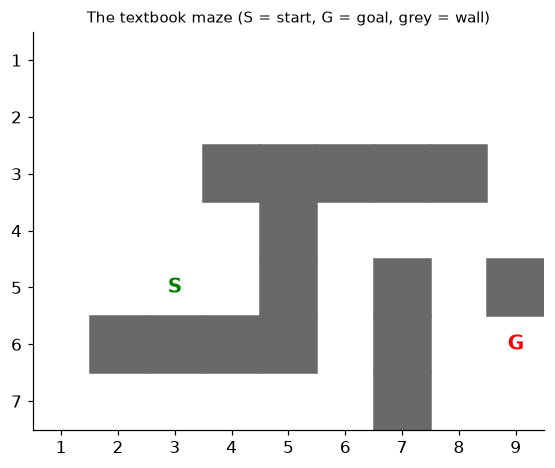

In [18]:
SIZE = (7, 9)
START, END = (5, 3), (6, 9)
OBSTACLES = {(3, 4), (3, 5), (3, 6), (3, 7), (3, 8),
             (4, 5),
             (5, 5), (5, 7), (5, 9),
             (6, 2), (6, 3), (6, 4), (6, 5), (6, 7),
             (7, 7)}

def neighbours(state, size=SIZE, obstacles=OBSTACLES):
    '''The successor function: legal up/down/left/right moves.'''
    r, c = state
    for dr, dc in ((-1, 0), (0, -1), (1, 0), (0, 1)):
        n = (r + dr, c + dc)
        if 1 <= n[0] <= size[0] and 1 <= n[1] <= size[1] and n not in obstacles:
            yield n

def draw_maze(ax, size=SIZE, obstacles=OBSTACLES, start=START, end=END,
              expanded=(), path=(), title=""):
    rows, cols = size
    ax.set_xlim(0.5, cols + 0.5); ax.set_ylim(rows + 0.5, 0.5); ax.set_aspect("equal")
    ax.set_xticks(range(1, cols + 1)); ax.set_yticks(range(1, rows + 1)); ax.grid(False)
    for (r, c) in obstacles:
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color="dimgrey"))
    for k, (r, c) in enumerate(expanded):
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, color="tab:orange", alpha=0.35))
    if path:
        ax.plot([c for _, c in path], [r for r, _ in path], color="tab:blue", lw=3, marker="o", ms=4)
    ax.text(start[1], start[0], "S", ha="center", va="center", fontsize=13, fontweight="bold", color="green")
    ax.text(end[1], end[0], "G", ha="center", va="center", fontsize=13, fontweight="bold", color="red")
    ax.set_title(title, fontsize=10)

fig, ax = plt.subplots(figsize=(6, 4.8))
draw_maze(ax, title="The textbook maze (S = start, G = goal, grey = wall)")
plt.show()

You can see two routes: **up and around the top** of the long wall, or **down and around the bottom**. The
computer can't see the picture. All it has is `neighbours()`. Notice that the only first move that brings you
*closer* to G is to step **right**, straight into a dead end. A good search has to recover from that.

We'll compare four searches. All of them follow **parent pointers** back from the goal to rebuild the path,
and all of them count how many cells they **expand** (take off the frontier and examine). That count is the
work the search did.

In [19]:
def reconstruct(parent, node):
    path = [node]
    while parent[node] is not None:
        node = parent[node]; path.append(node)
    return path[::-1]

def bfs(start, end, nbrs=neighbours):
    frontier, parent, expanded = deque([start]), {start: None}, []
    while frontier:
        node = frontier.popleft(); expanded.append(node)
        if node == end:
            return reconstruct(parent, node), expanded
        for s in nbrs(node):
            if s not in parent:                 # visited check: never queue a cell twice
                parent[s] = node; frontier.append(s)
    return None, expanded

def best_first(start, end, h, use_cost_so_far, nbrs=neighbours):
    '''use_cost_so_far=False -> greedy best-first (f = h);  True -> A* (f = g + h).'''
    g, parent, closed, expanded = {start: 0}, {start: None}, set(), []
    frontier, tie = [(h(start, end), 0, start)], 0          # (priority, tie-breaker, node)
    while frontier:
        _, _, node = heapq.heappop(frontier)
        if node in closed:
            continue                                         # stale duplicate entry
        closed.add(node); expanded.append(node)
        if node == end:
            return reconstruct(parent, node), expanded
        for s in nbrs(node):
            new_g = g[node] + 1
            if s not in closed and new_g < g.get(s, math.inf):
                g[s], parent[s] = new_g, node
                tie += 1
                f = (new_g if use_cost_so_far else 0) + h(s, end)
                heapq.heappush(frontier, (f, tie, s))
    return None, expanded

searches = {
    "BFS (uninformed)":           lambda: bfs(START, END),
    "Greedy, Manhattan (f = h)":  lambda: best_first(START, END, manhattan, False),
    "A*, Euclidean (f = g + h)":  lambda: best_first(START, END, euclidean, True),
    "A*, Manhattan (f = g + h)":  lambda: best_first(START, END, manhattan, True),
}
results = {}
for name, run in searches.items():
    path, expanded = run()
    results[name] = (path, expanded)
    print(f"{name:28s} path length = {len(path) - 1:2d} steps | cells expanded = {len(expanded)}")

BFS (uninformed)             path length = 15 steps | cells expanded = 47
Greedy, Manhattan (f = h)    path length = 17 steps | cells expanded = 23
A*, Euclidean (f = g + h)    path length = 15 steps | cells expanded = 43
A*, Manhattan (f = g + h)    path length = 15 steps | cells expanded = 41


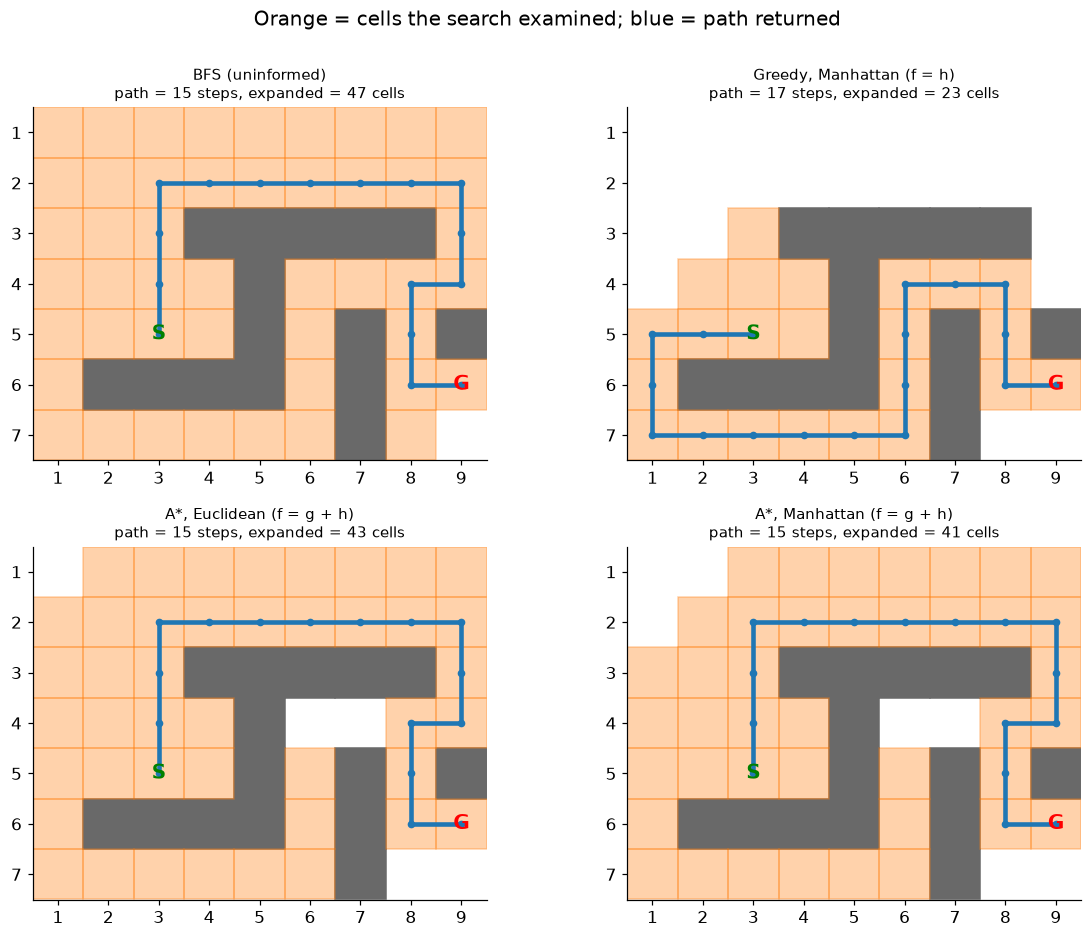

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, (name, (path, expanded)) in zip(axes.ravel(), results.items()):
    draw_maze(ax, expanded=expanded, path=path,
              title=f"{name}\npath = {len(path) - 1} steps, expanded = {len(expanded)} cells")
plt.suptitle("Orange = cells the search examined; blue = path returned", y=1.0)
plt.tight_layout(); plt.show()

What the four panels show:

- **BFS** spreads out evenly in every direction (a "flood fill") and finds the 15-step path. It's correct, but
  it examines almost the whole maze.
- **Greedy best-first** (priority = $h$ only) rushes toward the goal. It examines fewer cells, but **returns a
  17-step path, not the shortest**. It only ever asks "which cell looks closest to G?" and never "how far have
  I already walked?", so it commits to the route that *looked* good early on.
- **A\*** ranks cells by
  $$f(n) = \underbrace{g(n)}_{\text{steps taken so far}} + \underbrace{h(n)}_{\text{estimated steps left}}$$
  and returns the **optimal 15-step path**, guaranteed, because both heuristics are admissible on a
  4-direction grid. With Euclidean $h$ it expands **43 cells**, the same count the book reports.

**Why does admissibility guarantee the shortest path?** When A\* takes the goal off the frontier, its
$f = g$ is an exact path length, because $h(\text{goal}) = 0$. Every other node still on the frontier has
$f \ge$ that value, and since $h$ never overestimates, $f$ is a *lower bound* on any path through that node.
So no path left unexplored can be shorter.

> **⚠️ Textbook checks for this section.**
> 1. The book describes A\* as storing children "in the order of their **distance from the goal**". That's
>    *greedy* search, the method that just returned a 17-step path. A\* orders by $g + h$.
> 2. The book's BFS needs **110** steps because it has no shared visited set: the same cell gets queued again
>    and again by different neighbours. With a visited check (above), BFS expands at most one entry per free
>    cell, 47 here.
> 3. The book's `astar` removes old frontier entries with a list comprehension, which **breaks the heap
>    ordering** that `heapq` relies on. Pushing duplicates and skipping stale ones on pop (our `closed`
>    check) is the standard fix.

### Where A* really pays off: open spaces

In a cramped maze every route has to go around the same walls, so even A\* has to examine most cells. On a
large, mostly open map, which is the kind game engines and GPS route planners deal with, the difference is
dramatic:

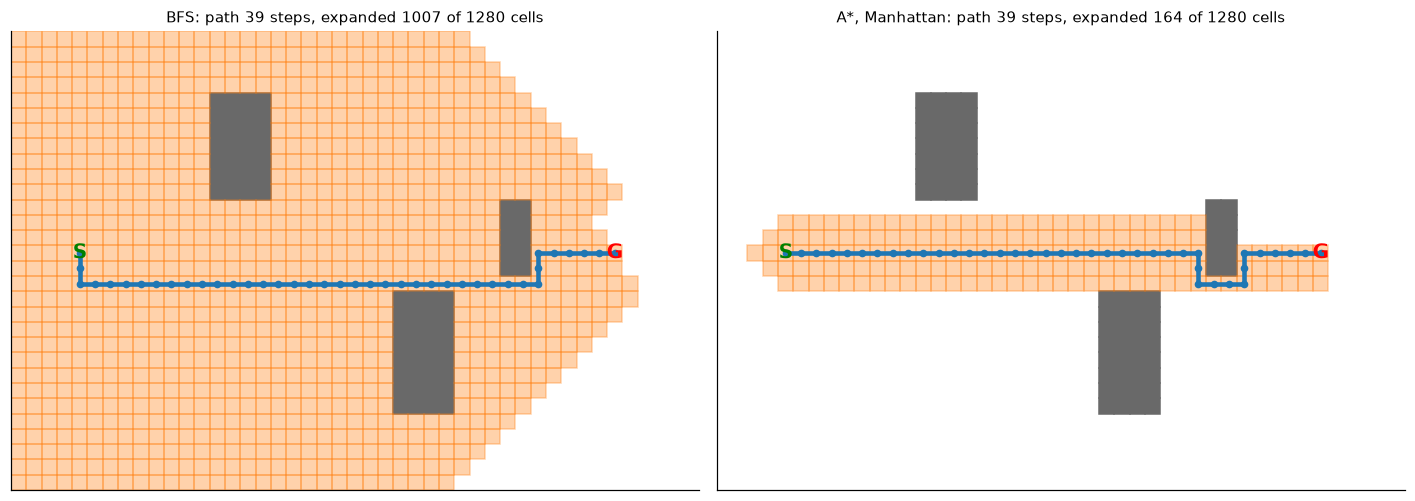

In [21]:
BIG = (30, 45)
big_obstacles = ({(r, c) for r in range(5, 12) for c in range(14, 18)} |     # a few buildings in the way
                 {(r, c) for r in range(18, 26) for c in range(26, 30)} |
                 {(r, c) for r in range(12, 17) for c in range(33, 35)})
big_start, big_end = (15, 5), (15, 40)
big_nbrs = lambda s: neighbours(s, size=BIG, obstacles=big_obstacles)

big = {"BFS": bfs(big_start, big_end, nbrs=big_nbrs),
       "A*, Manhattan": best_first(big_start, big_end, manhattan, True, nbrs=big_nbrs)}
free_cells = BIG[0] * BIG[1] - len(big_obstacles)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, (path, expanded)) in zip(axes, big.items()):
    draw_maze(ax, size=BIG, obstacles=big_obstacles, start=big_start, end=big_end,
              expanded=expanded, path=path,
              title=f"{name}: path {len(path) - 1} steps, expanded {len(expanded)} of {free_cells} cells")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

Both find a path of the same length, but A\* examines only a small fraction of the map. That's what an
informed search buys you: **the same optimal answer for far less work**. The saving depends on the map,
though. When a long wall stands right between start and goal, A\* first has to fill the "pocket" in front of
it, as in the textbook maze, and the saving shrinks.

> **Libraries.** The book also solves this maze with the `simpleai` library's `SearchProblem` + `astar`
> classes. It still works (`pip install simpleai`), but writing the algorithm yourself teaches more, and the
> code above does the same job. Section 13 has the details.

---
## 9. Two-player games: the Minimax algorithm

Pathfinding has a single agent. In a game, **an opponent moves between your turns**, trying to make things
as bad for you as possible. We can't just pick the branch with the best outcome, because the opponent decides
half of the branches.

**Minimax** assumes the opponent plays perfectly and works backwards from the leaves:

- At **our** turn (MAX), choose the child with the **highest** value.
- At **their** turn (MIN), they choose the child with the **lowest** value.
- At a **leaf** (game over, or our search depth runs out), use a static evaluation, i.e. a heuristic.

$$
\text{minimax}(s) =
\begin{cases}
\text{utility}(s) & \text{if } s \text{ is terminal or depth} = 0\\
\max_{s' \in \text{succ}(s)} \text{minimax}(s') & \text{if it's MAX's turn}\\
\min_{s' \in \text{succ}(s)} \text{minimax}(s') & \text{if it's MIN's turn}
\end{cases}
$$

Try it on a small tree first. The leaves are heuristic scores from MAX's point of view. Values move **up**
the tree: MAX levels take the larger child value, MIN levels take the smaller.

Minimax value of the root: 8
Leaves evaluated: 12 of 12


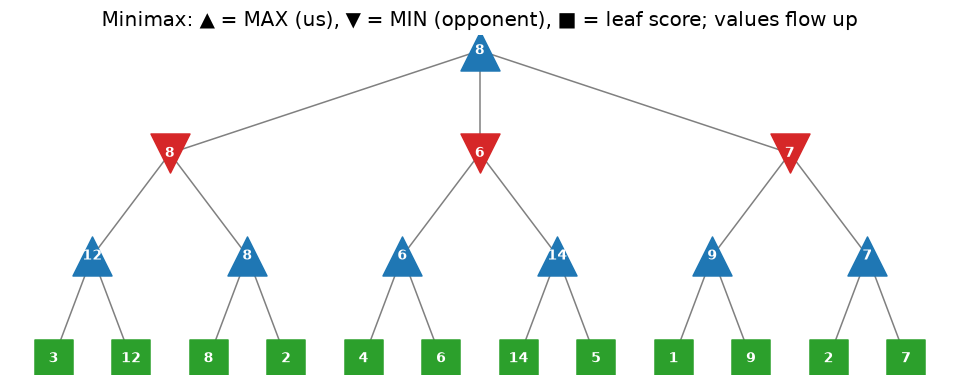

In [22]:
# A depth-3 game tree: MAX -> MIN -> MAX -> leaves
TOY = [[[3, 12], [8, 2]],
       [[4, 6], [14, 5]],
       [[1, 9], [2, 7]]]

def toy_minimax(node, maximizing, trace):
    if isinstance(node, int):
        trace.append(node); return node
    vals = [toy_minimax(ch, not maximizing, trace) for ch in node]
    return max(vals) if maximizing else min(vals)

trace = []
print("Minimax value of the root:", toy_minimax(TOY, True, trace))
print(f"Leaves evaluated: {len(trace)} of {len(trace)}")

def draw_game_tree(tree, ax, values_fn, pruned=frozenset(), title=""):
    '''Draw a nested-list tree; values_fn(path) gives the number to print at each node.'''
    pos, leaves = {}, [0]
    def place(node, path, depth):
        if isinstance(node, int):
            pos[path] = (leaves[0], -depth); leaves[0] += 1; return
        for i, ch in enumerate(node):
            place(ch, path + (i,), depth + 1)
        xs = [pos[path + (i,)][0] for i in range(len(node))]
        pos[path] = (sum(xs) / len(xs), -depth)
    place(tree, (), 0)
    for p, (x, y) in pos.items():
        if p:
            px, py = pos[p[:-1]]
            ax.plot([px, x], [py, y], color="lightgrey" if p in pruned else "grey", lw=1, zorder=1)
    leaves = {p for p in pos if not any(len(q) > len(p) and q[:len(p)] == p for q in pos)}
    for p, (x, y) in pos.items():
        is_max, grey = len(p) % 2 == 0, p in pruned
        marker = "s" if p in leaves else ("^" if is_max else "v")
        colour = "tab:green" if p in leaves else ("tab:blue" if is_max else "tab:red")
        ax.scatter(x, y, s=650, marker=marker, zorder=2, color="lightgrey" if grey else colour)
        v = values_fn(p)
        ax.text(x, y, "" if v is None else str(v), ha="center",
                va="center", color="white", fontsize=9, fontweight="bold", zorder=3)
    ax.set_title(title); ax.axis("off")

def toy_values(tree):
    vals = {}
    def go(node, path, maximizing):
        if isinstance(node, int):
            vals[path] = node; return node
        v = [go(ch, path + (i,), not maximizing) for i, ch in enumerate(node)]
        vals[path] = max(v) if maximizing else min(v); return vals[path]
    go(tree, (), True); return vals

vals = toy_values(TOY)
fig, ax = plt.subplots(figsize=(11, 4))
draw_game_tree(TOY, ax, vals.get,
               title="Minimax: ▲ = MAX (us), ▼ = MIN (opponent), ■ = leaf score; values flow up")
plt.show()

Check one branch by hand. Left subtree: the MAX nodes pick $\max(3,12)=12$ and $\max(8,2)=8$, then the MIN
node picks $\min(12,8)=8$. The other MIN nodes get $\min(6,14)=6$ and $\min(9,7)=7$. The root (MAX) picks
$\max(8,6,7)=8$. **Take the left branch.** Even though the tree contains a leaf worth 14, we can't reach it,
because the opponent would never allow it.

### Minimax plays perfect Tic-Tac-Toe

Tic-Tac-Toe is small enough to search **all the way to the end**. Then the evaluation only has to score
finished games: win $> 0$, loss $< 0$, draw $= 0$. A win scores $10 - (\text{marks on the board})$, so the AI
prefers *faster* wins and *slower* losses.

In [23]:
NODES = [0]       # global node counter, so we can compare algorithms' work

def terminal_score(board):
    '''Score a finished game from X's point of view; quicker wins are worth more.'''
    marks = 9 - board.count(EMPTY)
    w = winner(board)
    if w == AI:  return 10 - marks
    if w == OPP: return marks - 10
    return 0

def minimax(board, turn):
    NODES[0] += 1
    if is_over(board):
        return terminal_score(board)
    scores = [minimax(b, other(turn)) for b in all_moves(board, turn)]
    return max(scores) if turn == AI else min(scores)

NODES[0] = 0
t0 = time.time()
value = minimax(EMPTY * 9, AI)
mm_nodes, mm_time = NODES[0], time.time() - t0
print(f"Minimax value of the empty board: {value}  (0 = draw with perfect play)")
print(f"Positions searched: {mm_nodes:,} in {mm_time:.2f}s")

Minimax value of the empty board: 0  (0 = draw with perfect play)
Positions searched: 549,946 in 0.43s


The value of the empty board is **0**: Tic-Tac-Toe is a **draw** if both sides play perfectly. Searching
every line from the start takes about half a million positions.

But most of that work is repeated. Remember Section 6's trick #3, *merging permutations*: different move
orders reach the same board. If we **cache** each board's value the first time we compute it (a
*transposition table*), we never search the same position twice:

In [24]:
from functools import lru_cache

@lru_cache(maxsize=None)
def minimax_memo(board, turn):
    '''Exactly the same algorithm as minimax(), but each (board, turn) is solved only once.'''
    if is_over(board):
        return terminal_score(board)
    scores = [minimax_memo(b, other(turn)) for b in all_moves(board, turn)]
    return max(scores) if turn == AI else min(scores)

print(f"Cached minimax value: {minimax_memo(EMPTY * 9, AI)}")
print(f"Distinct positions actually solved: {minimax_memo.cache_info().currsize:,} "
      f"(instead of {mm_nodes:,} visits)")

Cached minimax value: 0
Distinct positions actually solved: 5,478 (instead of 549,946 visits)


Only **5,478** distinct positions are reachable in Tic-Tac-Toe. The other ~545,000 visits were repeats. With
the cache, playing a whole game takes milliseconds. Now turn the search into a player. At each turn, evaluate
every move and play the best one:

In [25]:
def best_move(board, sign, search):
    '''Pick the move whose searched value is best for `sign` (max for X, min for O).'''
    scored = [(search(b, other(sign)), b) for b in all_moves(board, sign)]
    best = (max if sign == AI else min)(s for s, _ in scored)
    return rng.choice([b for s, b in scored if s == best])    # break ties randomly

minimax_policy = lambda board, sign: best_move(board, sign, minimax_memo)

print("Minimax X vs random O (200 games):", tournament(minimax_policy, random_policy, n=200))
print("random X vs Minimax O (200 games):", tournament(random_policy, minimax_policy, n=200))
print("Minimax X vs Minimax O (20 games): ", tournament(minimax_policy, minimax_policy, n=20))

Minimax X vs random O (200 games): {'X wins': 193, 'O wins': 0, 'draw': 7}
random X vs Minimax O (200 games): {'X wins': 0, 'O wins': 158, 'draw': 42}
Minimax X vs Minimax O (20 games):  {'X wins': 0, 'O wins': 0, 'draw': 20}


**Zero losses** in every match-up, and perfect play against perfect play is always a draw. Nobody wrote a
rule like "take the corner" or "block the fork". The AI worked out how to avoid every losing line by
**searching**.

Want to try it yourself? Set `INTERACTIVE = True` in Setup and run the next cell. You play `O`, and you enter
cells as 0–8, numbered left to right, top to bottom.

In [26]:
def human_policy(board, sign):
    print_board(board)
    while True:
        cell = int(input(f"Your move as {sign} (0-8): "))
        if 0 <= cell <= 8 and board[cell] == EMPTY:
            return board[:cell] + sign + board[cell + 1:]
        print("That cell isn't free, try again.")

def play_vs(ai_policy):
    final = play_game(ai_policy, human_policy)
    print_board(final)
    print({AI: "AI wins.", OPP: "You win!"}.get(winner(final), "Draw."))

if INTERACTIVE:
    play_vs(minimax_policy)
else:
    print("Skipped: set INTERACTIVE = True in Setup to play.")

Skipped: set INTERACTIVE = True in Setup to play.


---
## 10. Alpha-beta pruning: same answer, a fraction of the work

Look back at the toy tree. Once the left branch is worth **8** to us, consider the middle MIN node. As soon as
its first child comes back worth **6**, we know the MIN node is worth *at most* 6, because MIN will never pick
anything higher. 6 < 8, so **we'd never choose this branch**, whatever its other children are worth. We can
skip them. That's a **cut-off**.

Alpha-beta tracks two bounds as it searches:

- $\alpha$: the best value **MAX** can already guarantee on the path so far (starts at $-\infty$),
- $\beta$: the best value **MIN** can already guarantee (starts at $+\infty$).

As soon as $\alpha \ge \beta$, the rest of that node's children can't change the decision, so we stop.

Alpha-beta root value: 8  (same as minimax: 8)
Leaves evaluated: 10 of 12


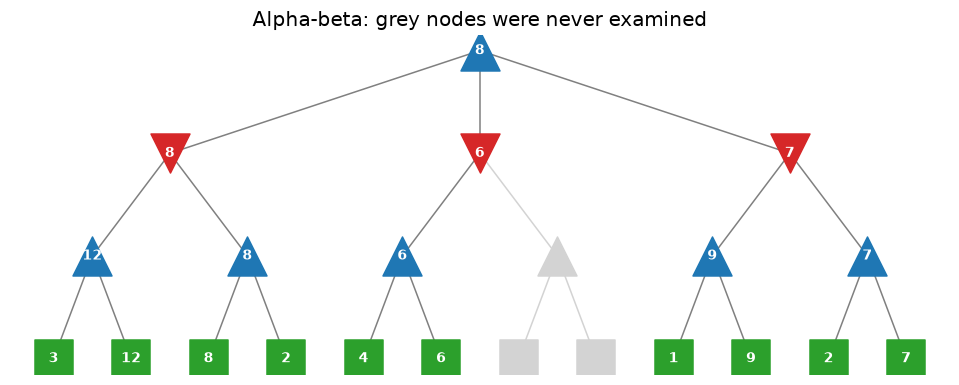

In [27]:
def toy_alphabeta(node, maximizing, alpha, beta, path, visited):
    visited.add(path)
    if isinstance(node, int):
        return node
    best = -math.inf if maximizing else math.inf
    for i, ch in enumerate(node):
        v = toy_alphabeta(ch, not maximizing, alpha, beta, path + (i,), visited)
        if maximizing:
            best = max(best, v); alpha = max(alpha, best)
        else:
            best = min(best, v); beta = min(beta, best)
        if alpha >= beta:
            break                                   # cut-off: skip the remaining children
    return best

visited = set()
root_value = toy_alphabeta(TOY, True, -math.inf, math.inf, (), visited)
all_paths = set(toy_values(TOY))
pruned = all_paths - visited
leaves_seen = sum(1 for p in visited if len(p) == 3)
print(f"Alpha-beta root value: {root_value}  (same as minimax: {toy_values(TOY)[()]})")
print(f"Leaves evaluated: {leaves_seen} of 12")

fig, ax = plt.subplots(figsize=(11, 4))
draw_game_tree(TOY, ax, lambda p: None if p in pruned else toy_values(TOY)[p], pruned=pruned,
               title="Alpha-beta: grey nodes were never examined")
plt.show()

Same root value, fewer leaves. On the full Tic-Tac-Toe tree the savings are much bigger:

In [28]:
def alphabeta(board, turn, alpha=-math.inf, beta=math.inf):
    NODES[0] += 1
    if is_over(board):
        return terminal_score(board)
    if turn == AI:                                   # MAX
        value = -math.inf
        for b in all_moves(board, turn):
            value = max(value, alphabeta(b, OPP, alpha, beta))
            alpha = max(alpha, value)
            if alpha >= beta: break
    else:                                            # MIN
        value = math.inf
        for b in all_moves(board, turn):
            value = min(value, alphabeta(b, AI, alpha, beta))
            beta = min(beta, value)
            if alpha >= beta: break
    return value

NODES[0] = 0
t0 = time.time()
ab_value = alphabeta(EMPTY * 9, AI)
ab_nodes, ab_time = NODES[0], time.time() - t0
print(f"Minimax:    value {value}, {mm_nodes:>8,} positions, {mm_time:.2f}s")
print(f"Alpha-beta: value {ab_value}, {ab_nodes:>8,} positions, {ab_time:.2f}s")
print(f"-> {mm_nodes / ab_nodes:.0f}x fewer positions for exactly the same answer")

Minimax:    value 0,  549,946 positions, 0.43s
Alpha-beta: value 0,   20,866 positions, 0.02s
-> 26x fewer positions for exactly the same answer


That saving is why real game engines can search much **deeper** in the same time, and deeper search usually
means stronger play. Move ordering matters too: if the best moves are tried first, cut-offs happen sooner. In
the best case alpha-beta searches about $\sqrt{N}$ of the $N$ positions minimax would.

> **⚠️ Textbook check: alpha-beta bugs.** The book's pseudocode has two bugs that change the answer:
>
> 1. It starts the search with **`alpha = infinity, beta = -infinity`**, which is backwards. It must be
>    $\alpha = -\infty$, $\beta = +\infty$ ("nothing guaranteed yet").
> 2. Its MAX branch starts with **`utility = 0`** instead of $-\infty$. If every move is bad (all children
>    negative), it wrongly reports 0.
>
> Here is what each bug does:

In [29]:
NODES[0] = 0
wrong = alphabeta(EMPTY * 9, AI, alpha=math.inf, beta=-math.inf)
print(f"Book's swapped initial bounds -> value {wrong} after only {NODES[0]} positions "
      f"(correct value is {ab_value}: it pruned almost everything)")

def minimax_book_init(board, turn):
    if is_over(board):
        return terminal_score(board)
    if turn == AI:
        utility = 0                                   # the book's bug (should be -inf)
        for b in all_moves(board, turn):
            utility = max(utility, minimax_book_init(b, OPP))
        return utility
    return min(minimax_book_init(b, AI) for b in all_moves(board, turn))

lost = "O.OXOX.X."   # X to move, but O threatens cells 1, 6 and 8 at once -- X loses whatever it does
print_board(lost)
print(f"Correct minimax value: {minimax(lost, AI)}  (negative: X is lost)")
print(f"Book's 'utility = 0' version: {minimax_book_init(lost, AI)}  (wrongly says it's fine)")

Book's swapped initial bounds -> value 3 after only 8 positions (correct value is 0: it pruned almost everything)
 O | . | O
 X | O | X
 . | X | .

Correct minimax value: -2  (negative: X is lost)
Book's 'utility = 0' version: 0  (wrongly says it's fine)


---
## 11. Negamax: one branch instead of two

The MAX and MIN branches in `alphabeta` mirror each other. The book cites the **DRY** principle
(*Don't Repeat Yourself*): code written twice is twice as likely to contain a bug. In a **zero-sum** game, a
position worth $+v$ to one player is worth $-v$ to the other, so

$$\min(a, b) = -\max(-a, -b).$$

**Negamax** always scores from the point of view of **the player about to move**, and flips the sign when it
passes the turn:

$$\text{negamax}(s) = \max_{s' \in \text{succ}(s)} \big(-\text{negamax}(s')\big).$$

In [30]:
def negamax(board, turn, alpha=-math.inf, beta=math.inf):
    '''Value of `board` for the player `turn` who is about to move (with alpha-beta).'''
    NODES[0] += 1
    if is_over(board):
        score_for_x = terminal_score(board)
        return score_for_x if turn == AI else -score_for_x
    best = -math.inf
    for b in all_moves(board, turn):
        best = max(best, -negamax(b, other(turn), -beta, -alpha))
        alpha = max(alpha, best)
        if alpha >= beta: break
    return best

NODES[0] = 0
print(f"Negamax (with alpha-beta) value: {negamax(EMPTY * 9, AI)}, positions: {NODES[0]:,}")
print(f"Alpha-beta value:                {ab_value}, positions: {ab_nodes:,}")

Negamax (with alpha-beta) value: 0, positions: 20,866
Alpha-beta value:                0, positions: 20,866


Same value, same number of positions, half the code. The alpha-beta window flips too
(`-beta, -alpha`): what was "the best the opponent can force" becomes "the best I can force" once you change
point of view.

> **⚠️ Textbook check.** The book's `Negamax` pseudocode never negates the child's score, never takes a
> maximum, and returns only the **last** child's score (`return score`). It works only as a sketch of the
> idea. Use the version above. Also note the condition the book *does* state correctly: Negamax needs a
> **symmetric** evaluation (if a position is worth +20 to one player, it's worth −20 to the other).

---
## 12. Connect Four: when you can't search to the end (textbook Activity 4)

Connect Four: **7 columns × 6 rows**. (The book says "seven cells high"; the standard board, and the book's
own solution code, use 6.) You drop a token into a column, it falls to the lowest empty cell, and four in a
row in any direction wins. The game has about $4.5 \times 10^{12}$ legal positions. That's tiny next to chess,
but still far too many to search to the end in Python.

So we use what real game engines use: **depth-limited Negamax with alpha-beta**, plus a **heuristic
evaluation** for positions where the search stops before the game ends. Our heuristic looks at every
4-cell "window" (all 69 possible lines of four):

| Window contains | Score (for the player to move) |
|---|---|
| 3 of mine + 1 empty | +5 |
| 2 of mine + 2 empty | +2 |
| 3 of the opponent's + 1 empty | −4 |
| each of my tokens in the centre column | +3 (the centre is on the most windows) |

In [31]:
C4_ROWS, C4_COLS = 6, 7

def c4_new():
    return np.zeros((C4_ROWS, C4_COLS), dtype=int)       # 0 empty, 1 = player 1, 2 = player 2

def c4_moves(board):
    return [c for c in range(C4_COLS) if board[0, c] == 0]

def c4_drop(board, col, player):
    b = board.copy()
    row = max(r for r in range(C4_ROWS) if b[r, col] == 0)    # gravity: lowest empty cell
    b[row, col] = player
    return b

# All 69 windows of four cells, precomputed once (the book's "winning tuples")
WINDOWS = []
for r in range(C4_ROWS):
    for c in range(C4_COLS):
        for dr, dc in ((0, 1), (1, 0), (1, 1), (-1, 1)):       # right, down, diagonal down, diagonal up
            cells = [(r + k * dr, c + k * dc) for k in range(4)]
            if all(0 <= rr < C4_ROWS and 0 <= cc < C4_COLS for rr, cc in cells):
                WINDOWS.append(tuple(np.array(cells).T))
print(f"{len(WINDOWS)} winning lines of four on a 6x7 board")

def c4_wins(board, player):
    return any((board[w] == player).all() for w in WINDOWS)

def c4_evaluate(board, player):
    opp, score = 3 - player, 3 * int((board[:, C4_COLS // 2] == player).sum())
    for w in WINDOWS:
        cells = board[w]
        mine, theirs, empty = (cells == player).sum(), (cells == opp).sum(), (cells == 0).sum()
        if mine == 3 and empty == 1:     score += 5
        elif mine == 2 and empty == 2:   score += 2
        if theirs == 3 and empty == 1:   score -= 4
    return score

def c4_negamax(board, depth, alpha, beta, player):
    opp = 3 - player
    if c4_wins(board, opp):
        return -1_000_000 - depth          # opponent just won: very bad; losing later is less bad
    moves = c4_moves(board)
    if not moves:
        return 0                           # board full: draw
    if depth == 0:
        return c4_evaluate(board, player)  # out of search budget: trust the heuristic
    best = -math.inf
    for col in sorted(moves, key=lambda c: abs(c - 3)):   # try centre columns first -> more cut-offs
        best = max(best, -c4_negamax(c4_drop(board, col, player), depth - 1, -beta, -alpha, opp))
        alpha = max(alpha, best)
        if alpha >= beta: break
    return best

def c4_ai(depth):
    def policy(board, player):
        scored = [(-c4_negamax(c4_drop(board, c, player), depth - 1, -math.inf, math.inf, 3 - player), c)
                  for c in c4_moves(board)]
        best = max(s for s, _ in scored)
        return rng.choice([c for s, c in scored if s == best])
    return policy

def c4_random(board, player):
    return rng.choice(c4_moves(board))

def c4_show(board):
    print("\n".join(" ".join(".XO"[v] for v in row) for row in board))
    print(" ".join(str(c) for c in range(C4_COLS)))

69 winning lines of four on a 6x7 board


In [32]:
def c4_play(p1, p2, random_opening=0):
    board, player = c4_new(), 1
    for _ in range(random_opening):                        # a few random moves = varied games
        board = c4_drop(board, c4_random(board, player), player); player = 3 - player
    while True:
        col = (p1 if player == 1 else p2)(board, player)
        board = c4_drop(board, col, player)
        if c4_wins(board, player): return player, board
        if not c4_moves(board):    return 0, board
        player = 3 - player

def c4_tournament(p1, p2, n, random_opening=0):
    tally = Counter(c4_play(p1, p2, random_opening)[0] for _ in range(n))
    return {"P1 wins": tally[1], "P2 wins": tally[2], "draws": tally[0]}

t0 = time.time()
print("AI (depth 4) vs random, 10 games:      ", c4_tournament(c4_ai(4), c4_random, 10))
print("random vs AI (depth 4), 10 games:      ", c4_tournament(c4_random, c4_ai(4), 10))
print("AI depth 4 vs AI depth 2, 6 games:     ", c4_tournament(c4_ai(4), c4_ai(2), 6, random_opening=2))
print("AI depth 2 vs AI depth 4, 6 games:     ", c4_tournament(c4_ai(2), c4_ai(4), 6, random_opening=2))
print(f"({time.time() - t0:.0f}s)")

AI (depth 4) vs random, 10 games:       {'P1 wins': 10, 'P2 wins': 0, 'draws': 0}


random vs AI (depth 4), 10 games:       {'P1 wins': 0, 'P2 wins': 10, 'draws': 0}


AI depth 4 vs AI depth 2, 6 games:      {'P1 wins': 4, 'P2 wins': 2, 'draws': 0}


AI depth 2 vs AI depth 4, 6 games:      {'P1 wins': 1, 'P2 wins': 5, 'draws': 0}
(37s)


Two results stand out:

- The depth-4 AI **beats a random player in every game**, whichever side it plays.
- **Deeper search wins.** Depth 4 wins most games against depth 2, from either side. Same heuristic, same
  code. Looking further ahead is the only difference. (Depth 2 still takes a few games. A depth-limited
  search can be fooled by a threat just beyond its horizon, so it isn't perfect play like the full
  Tic-Tac-Toe search.) That's why alpha-beta's savings matter so much: the time you save is time you
  can spend searching deeper.

One sample game, AI (X) vs random (O):

In [33]:
result, final_board = c4_play(c4_ai(4), c4_random)
c4_show(final_board)
print({1: "X (AI) wins", 2: "O (random) wins", 0: "draw"}[result])

. . . . . . .
. . . . . . .
. . . . X . .
. . . . X . .
. O . X X . .
O O . X X O O
0 1 2 3 4 5 6
X (AI) wins


In [34]:
def c4_human(board, player):
    c4_show(board)
    while True:
        col = int(input(f"Your column (0-6): "))
        if col in c4_moves(board):
            return col
        print("Column full or invalid.")

if INTERACTIVE:
    result, final_board = c4_play(c4_human, c4_ai(4))
    c4_show(final_board); print({1: "You win!", 2: "AI wins.", 0: "Draw."}[result])
else:
    print("Skipped: set INTERACTIVE = True in Setup to play Connect Four against the depth-4 AI.")

Skipped: set INTERACTIVE = True in Setup to play Connect Four against the depth-4 AI.


---
## 13. Libraries, and textbook corrections

### The book's libraries today

| Library | Book uses it for | Status in 2026 |
|---|---|---|
| `simpleai` | A\* on the maze (`SearchProblem`, `astar`) | Still installs and works (`pip install simpleai`). The book's class has two bugs: it uses `self._obstacles` while the constructor sets `self.obstacles`, and `is_goal` compares to a global `end` instead of `self.end`. |
| `easyAI` | Negamax Tic-Tac-Toe and Connect Four | **The book's code doesn't run on current versions.** The latest release fails on import, and 2.x renamed `TwoPlayersGame` → `TwoPlayerGame` and `nplayer` → `current_player`. The book's examples only run on `pip install easyAI==1.0.0.4`. |

Both libraries wrap the same algorithms this notebook builds by hand, and the hand-built versions are easier
to read and debug.

### Corrections to Chapters 1–2

| Where | What the book says | Correction |
|---|---|---|
| Ch 1, NumPy | `np.mat(...)`, `A * A` for matrix product | `np.mat` was removed in NumPy 2.0. Use `np.array` and `A @ A`. |
| Ch 1, BFS/DFS | First listing is introduced as "DFS" but is BFS; typo `visited_bodes` | Section 4. BFS uses a queue (`popleft`), DFS a stack (`pop`). |
| Ch 1, Exercise 3 | Defines `all_moves_from_board_list` but calls `all_moves_from_board` | Name mismatch: the code raises `NameError`. |
| Ch 1, Activity 1 | 266,073 possible games | **255,168**. `filter_wins` removes items from a list while iterating over it (Section 5). |
| Ch 1, Turing test | Predicted to be passed "in the late 2020s" | Text-only Turing tests were already being passed by LLMs in 2025 (Section 1). |
| Ch 2, Exercise 4 / Activities 2–3 | 91,344 / 42,048 / 188 games | Affected by the same counting bug. The verified figures are in Section 6. |
| Ch 2, Exercise 5 | The heuristic player loses 12 games | As X (first player) it loses **0** of 248 games. It *does* lose as O: 120 ways, via forks (Section 7). |
| Ch 2, Exercise 7 | BFS reaches the goal in 110 steps | Duplicates are queued because there's no shared visited set. With one, BFS expands 47 cells. |
| Ch 2, A\* description | Children sorted "by distance from the goal" | That's greedy search. A\* sorts by $g + h$ (Section 8). |
| Ch 2, A\* code | Filters entries out of a `heapq` list with a comprehension | Breaks the heap invariant. Push duplicates and skip closed nodes instead. |
| Ch 2, Minimax | MAX branch starts with `utility = 0` | Must start at $-\infty$ (Section 10 demo). |
| Ch 2, Alpha-beta | Initial `alpha = infinity`, `beta = -infinity` | Swapped. $\alpha = -\infty$, $\beta = +\infty$ (Section 10 demo). |
| Ch 2, Negamax | No negation, no max, returns last child's score | Section 11. |
| Ch 2, Activity 4 | Connect Four board "seven cells high" | 7 columns × 6 rows, as the book's own solution code uses. |

### What heuristic search looks like today

The ideas in this module still run real systems. **Route planners** and **game characters** use A\* and
its descendants. **Chess engines** like Stockfish use alpha-beta search with a hand-tuned (and now partly
learned) evaluation. **AlphaGo** and **AlphaZero** (2016–2017) combined game-tree search (Monte Carlo Tree
Search) with **neural networks** that learned the evaluation function. That combination of search from this
module and learning from the rest of the course beat world champions at Go.

---
## 14. Your turn

Add cells below each exercise. Exercises 3 and 5 consolidate the main ideas.

**Exercise 1 — An agent with memory.**
The reflex vacuum agent in Section 2 keeps moving after both rooms are clean. Write an agent that remembers
which rooms it has seen clean (use a `set` defined outside the function, or a small class) and returns
`"NoOp"` once both are clean. Update `run_vacuum_world` so `"NoOp"` costs nothing, and compare the scores.

**Exercise 2 — Symmetry.**
The book says the four corner openings are equivalent. Write `rotate(board)` (a 90° clockwise turn of the
9-character string) and `mirror(board)` (a left-right flip). Section 9 showed that 5,478 distinct positions
are reachable. Collect them all, map each to a *canonical* form (the alphabetically smallest of its 8
rotations and reflections), and count the unique canonical forms. You should get 765. By what factor does
symmetry shrink the space?

**Exercise 3 — Break admissibility on purpose.**
Re-run A\* on the textbook maze with `h = lambda a, b: 3 * manhattan(a, b)`. Does it still return a 15-step
path? How many cells does it expand? Explain the trade-off you see between speed and optimality, and why it
happens.

**Exercise 4 — Diagonal moves.**
Extend `neighbours()` to allow the four diagonal steps (each costing 1). Which of `euclidean` and `manhattan`
is still admissible? Run A\* with each and compare the path lengths against BFS, which is always optimal when
every step costs the same.

**Exercise 5 — A better Connect Four heuristic.**
Change the weights in `c4_evaluate` (or add a new feature, such as rewarding threats in lower rows, which
come into play sooner). Play your version against the original at depth 3 for 10 games with
`random_opening=2`. Report the result, and explain why your change helps or doesn't.

**Exercise 6 — Count the savings.**
Add a `NODES` counter to `c4_negamax` and compare the number of positions searched at depth 4 with and without
the centre-first move ordering (`sorted(moves, key=lambda c: abs(c - 3))` vs plain `moves`). Relate what you
find to alpha-beta's best case from Section 10.

---
## 15. If you remember nothing else

1. **AI ⊃ ML.** Machine learning is one route to artificial intelligence. Rules and search are others, and
   they need no training data at all. Every agent in this module was intelligent without learning anything.

2. An **intelligent agent** senses its environment, acts on it, and pursues a goal. Formally, it is a
   function from percepts to actions, judged by a performance measure.

3. To make an agent plan, describe the problem as a **state space** (initial state, successor function, goal
   test) and **search** it. **BFS** (a queue) finds the shallowest goal. **DFS** (a stack) dives deep and uses
   less memory. Keep a **visited set** whenever states can repeat.

4. State spaces **explode combinatorially**. Even Tic-Tac-Toe has 255,168 games. Every technique in this
   module (rules, symmetry, heuristics, pruning) is a way to avoid looking at most of them.

5. A **heuristic** is an educated guess about how good a state is or how far it is from the goal. It is
   **admissible** if it never overestimates the remaining cost, and that depends on which moves are allowed.

6. **A\*** expands nodes in order of $f = g + h$ (cost so far plus estimated cost left). With an admissible
   $h$ it always finds the shortest path, usually after examining far fewer states than BFS. **Greedy** search
   ($f = h$ only) is faster but can return longer paths.

7. **Minimax** handles opponents: MAX takes the highest child value, MIN the lowest, and values flow up from
   the leaves. On Tic-Tac-Toe it plays perfectly, and the game is a draw with best play on both sides.

8. **Alpha-beta pruning** returns *exactly* the minimax answer while skipping branches that can't change the
   decision. It searched about 26× fewer Tic-Tac-Toe positions. **Negamax** is the same algorithm in one
   branch, using $\min(a,b) = -\max(-a,-b)$.

9. When the game is too big to search to the end (Connect Four, chess), **cut the search at a fixed depth and
   score the leaves with a heuristic**. Deeper search beats shallower search, which is why pruning matters.

10. Read textbooks critically and **verify numbers by running code**. Several of this chapter's figures and
    pseudocode were wrong, and only running them showed it.

---
## 16. Further reading and glossary

### Further reading

- Zsolt Nagy (2018), *Artificial Intelligence and Machine Learning Fundamentals*, Packt. Chapters 1–2, the
  Week 3 reading (with the corrections in Section 13).
- Stuart Russell & Peter Norvig, [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/)
  (4th ed.). Chapters 2–6 are the standard reference for agents, search, heuristics and adversarial search.
- Amit Patel, [*Introduction to A\**](https://www.redblobgames.com/pathfinding/a-star/introduction.html).
  Interactive, visual explanations of BFS, Dijkstra, greedy best-first and A\*. Highly recommended.
- Hart, Nilsson & Raphael (1968), [*A Formal Basis for the Heuristic Determination of Minimum Cost Paths*](
  https://doi.org/10.1109/TSSC.1968.300136). The original A\* paper.
- Knuth & Moore (1975), [*An Analysis of Alpha-Beta Pruning*](https://doi.org/10.1016/0004-3702(75)90019-3).
  Why alpha-beta works and how much it saves.
- Silver et al. (2016), [*Mastering the game of Go with deep neural networks and tree search*](
  https://doi.org/10.1038/nature16961). AlphaGo: search and learning combined.
- Google for Developers, [*Introduction to Machine Learning Problem Framing*](
  https://developers.google.com/machine-learning/problem-framing). The Week 3 assignment course.

### Glossary

| Term | Meaning |
|---|---|
| Artificial intelligence | Building systems that behave intelligently, by any method: rules, search or learning. |
| Machine learning | Improving at a task $T$, measured by $P$, through experience $E$ (Mitchell). |
| Intelligent agent | An autonomous system that senses (sensors), acts (actuators) and pursues a goal. |
| State space | Every state a problem can be in, connected by the actions between them. |
| Successor function | Given a state, returns the states reachable in one action. |
| Search tree | The tree of states reached by repeatedly applying the successor function from the start. |
| BFS / DFS | Uninformed searches that visit level by level (queue) or branch by branch (stack). |
| Combinatorial explosion | The rapid, multiplicative growth of the number of states as depth increases. |
| Heuristic | An educated-guess function scoring a state's utility or estimated distance to the goal. |
| Admissible heuristic | One that never overestimates the true remaining cost. |
| Greedy best-first search | Expands the node with the smallest $h$. Fast, but not guaranteed optimal. |
| A\* | Expands the node with the smallest $g + h$. Optimal when $h$ is admissible. |
| Minimax | Game-tree search where MAX takes the highest child value and MIN the lowest. |
| Alpha-beta pruning | Minimax that skips branches which can't affect the decision. Same answer, less work. |
| Negamax | Minimax written as one branch, using $\min(a,b) = -\max(-a,-b)$ for zero-sum games. |
| Static evaluation | Scoring a non-terminal position with a heuristic when the search stops. |